# UAV Road Damage Detection — Cleaned Notebook (Outputs Preserved)

This is a cleanup of the final notebook that **preserves the already-generated results and figures**. It removes failed checkpoint-extraction attempts, duplicate/empty cells, and the interrupted training cell.

## Important
- This notebook is organized for reviewing and reporting the completed experiment.
- **Do not run training again.** The training cell has been removed from this report-focused copy.
- Existing evaluation outputs below are preserved from the original notebook. If you rerun evaluation, it will regenerate the metrics.
- Baseline checkpoint: `/content/baseline_weights_backup/best.pt`
- Custom checkpoint: `/content/dal_best.pt`
- Confirm the custom checkpoint architecture before claiming it is a full DAL-YOLO implementation.


## 1. Environment and reproducibility
The original environment output is retained below. Re-run this cell only if you need to recreate the Colab environment.

In [ ]:
# 1. Environment and reproducibility
%pip -q install -U ultralytics kaggle seaborn scikit-learn

import os, sys, json, random, shutil, subprocess, hashlib, platform, math, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from ultralytics import YOLO

SEED = 56
EPOCHS = 50           # Set to 1-3 for a smoke test, then restore to 300 for the real run
IMGSZ = 640
BATCH = 16             # Reduce to 8 or 4 if you run out of GPU memory
WORKERS = 2
PROJECT = Path('/content/uavroad_experiment')
DATA_ROOT = Path('/content/uavroad')
RUNS_DIR = PROJECT / 'runs'
PROJECT.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    # Prefer reproducibility; some CUDA ops may still be nondeterministic.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed()
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
import ultralytics
print('Ultralytics:', ultralytics.__version__)
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Run directory:', RUNS_DIR)


Python: 3.13.16
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.192
Device: Tesla T4
Run directory: /content/uavroad_experiment/runs


## 2. Dataset acquisition
The dataset-location output is retained. Re-run only if the dataset is not available in the current Colab session.

In [ ]:
# 2. Obtain dataset from Kaggle and locate the VOC source folders
# If kaggle.json is not already configured, upload it when prompted.
from pathlib import Path
source_root = Path('/content/uavroad_source')
source_root.mkdir(parents=True, exist_ok=True)

if not Path('/root/.kaggle/kaggle.json').exists() and not Path('/content/kaggle.json').exists():
    try:
        from google.colab import files
        print('Upload your Kaggle API token file (kaggle.json).')
        uploaded = files.upload()
        if 'kaggle.json' in uploaded:
            Path('/root/.kaggle').mkdir(parents=True, exist_ok=True)
            shutil.copy('/content/kaggle.json', '/root/.kaggle/kaggle.json')
            os.chmod('/root/.kaggle/kaggle.json', 0o600)
    except Exception as e:
        print('Could not open Colab upload dialog. Configure Kaggle credentials manually:', e)

if not Path('/root/.kaggle/kaggle.json').exists() and Path('/content/kaggle.json').exists():
    Path('/root/.kaggle').mkdir(parents=True, exist_ok=True)
    shutil.copy('/content/kaggle.json', '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

# Download only if the source folders are not already present.
def find_voc_dirs(root):
    candidates = []
    for p in root.rglob('*'):
        if p.is_dir() and p.name.lower() == 'jpegimages':
            ann = p.parent / 'Annotations'
            if ann.exists():
                candidates.append((p, ann))
    return candidates

voc_dirs = find_voc_dirs(source_root)
if not voc_dirs:
    archive = source_root / 'uavroad.zip'
    subprocess.run(['kaggle', 'datasets', 'download', '-d', 'sweetodd/uavroad', '-p', str(source_root)], check=False)
    # Retry with checked status below if the first download did not produce an archive.
    if not archive.exists():
        subprocess.run(['kaggle', 'datasets', 'download', '-d', 'sweetodd/uavroad', '-p', str(source_root)], check=True)
    import zipfile
    zips = list(source_root.glob('*.zip'))
    if not zips:
        raise FileNotFoundError('Kaggle download did not produce a ZIP. Check Kaggle credentials and dataset access.')
    for z in zips:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(source_root)
    voc_dirs = find_voc_dirs(source_root)

if not voc_dirs:
    raise FileNotFoundError('Could not find a JPEGImages folder with a sibling Annotations folder in the extracted dataset.')
SRC_IMG_DIR, SRC_ANN_DIR = voc_dirs[0]
print('Images:', SRC_IMG_DIR)
print('Annotations:', SRC_ANN_DIR)


Images: /content/uavroad_source/UAVROAD DATASET/JPEGImages
Annotations: /content/uavroad_source/UAVROAD DATASET/Annotations


## 3. Label conversion, class audit, and deterministic splits
The annotation audit and split outputs are preserved for reference. Re-run only if you need to recreate the dataset folders.

In [ ]:
# 3. Convert VOC XML labels, audit classes/boxes, and make deterministic 80/10/10 splits
# The mapping below preserves the mapping from the supplied notebook. Review aliases carefully:
# mapping semantically different categories to one class can reduce label quality.
CLASS_MAPPING = {
    'transverse crack': 0,
    'longitudinal crack': 1,
    'alligator crack': 2,
    'oblique crack': 3,
    'repair': 4,
    'pothole': 5,
    'marking': 6,
    'damaged marking': 6,
    'green belt': 7,
    'greenbelt encroachment': 7,
    'crosswalk': 7,
    'sign': 8,
    'damaged sign': 8,
    'guardrail': 9,
    'guardrails': 9,
    'damaged guardrail': 9,
    'damaged guardrails': 9,  # Fixed: plural alias
    'drainage': 10,
    'uncleandrain': 10,
    'cleandrain': 10,
    'damaged drainage': 10,
    'curb': 11,
    'damaged curb': 11,
    'trash': 12,
    'water': 13,
}

CLASS_NAMES = [
    'transverse crack',
    'longitudinal crack',
    'alligator crack',
    'oblique crack',
    'repair',
    'pothole',
    'damaged marking',
    'greenbelt encroachment',
    'damaged sign',
    'damaged guardrail',
    'damaged drainage',
    'damaged curb',
    'trash',
    'water',
]

assert sorted(set(CLASS_MAPPING.values())) == list(range(len(CLASS_NAMES)))


image_paths = sorted([p for p in SRC_IMG_DIR.iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png'}])
pairs = [(p, SRC_ANN_DIR / (p.stem + '.xml')) for p in image_paths if (SRC_ANN_DIR / (p.stem + '.xml')).exists()]
missing_xml = len(image_paths) - len(pairs)
if not pairs:
    raise RuntimeError('No image/XML pairs found.')
print(f'Images found: {len(image_paths)} | paired images: {len(pairs)} | missing XML: {missing_xml}')

# Validate all class names before writing labels; do not silently discard unknown classes.
unknown = {}
invalid_boxes = 0
class_counts = {name: 0 for name in CLASS_NAMES}
parsed = []
for img_path, xml_path in pairs:
    root = ET.parse(xml_path).getroot()
    size = root.find('size')
    if size is None or size.find('width') is None or size.find('height') is None:
        raise ValueError(f'Missing image dimensions in {xml_path}')
    iw, ih = float(size.find('width').text), float(size.find('height').text)
    if iw <= 0 or ih <= 0:
        raise ValueError(f'Invalid image dimensions in {xml_path}')
    labels = []
    for obj in root.findall('object'):
        name_node = obj.find('name')
        box = obj.find('bndbox')
        if name_node is None or box is None:
            invalid_boxes += 1
            continue
        raw = name_node.text.strip().lower()
        if raw not in CLASS_MAPPING:
            unknown[raw] = unknown.get(raw, 0) + 1
            continue
        try:
            x1, y1, x2, y2 = [float(box.find(k).text) for k in ('xmin','ymin','xmax','ymax')]
        except Exception:
            invalid_boxes += 1
            continue
        x1, x2 = np.clip([x1, x2], 0, iw)
        y1, y2 = np.clip([y1, y2], 0, ih)
        if x2 <= x1 or y2 <= y1:
            invalid_boxes += 1
            continue
        cls = CLASS_MAPPING[raw]
        xc, yc, bw, bh = ((x1+x2)/(2*iw), (y1+y2)/(2*ih), (x2-x1)/iw, (y2-y1)/ih)
        labels.append(f'{cls} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}')
        class_counts[CLASS_NAMES[cls]] += 1
    parsed.append((img_path, labels))

if unknown:
    print('UNMAPPED XML CLASSES (must be reviewed before final training):')
    display(pd.DataFrame(sorted(unknown.items(), key=lambda x: -x[1]), columns=['class_name','object_count']))
    raise ValueError('Unknown annotation classes found. Add deliberate mappings to CLASS_MAPPING before continuing; do not silently drop them.')
print('Malformed/invalid boxes skipped:', invalid_boxes)
display(pd.DataFrame(class_counts.items(), columns=['class_name','object_count']).sort_values('object_count', ascending=False))

# Remove only the generated split directories; never delete the downloaded source.
for sub in ['images/train','images/val','images/test','labels/train','labels/val','labels/test']:
    d = DATA_ROOT / sub
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True, exist_ok=True)

rng = random.Random(SEED)
rng.shuffle(parsed)
n = len(parsed)
n_train, n_val = int(n*0.8), int(n*0.1)
split_data = {'train': parsed[:n_train], 'val': parsed[n_train:n_train+n_val], 'test': parsed[n_train+n_val:]}
for split, rows in split_data.items():
    for img_path, label_lines in rows:
        dst_img = DATA_ROOT/'images'/split/img_path.name
        shutil.copy2(img_path, dst_img)
        (DATA_ROOT/'labels'/split/(img_path.stem+'.txt')).write_text('\n'.join(label_lines), encoding='utf-8')

dataset_yaml = DATA_ROOT/'uavroad.yaml'
yaml_text = 'path: '+str(DATA_ROOT)+'\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n'
yaml_text += ''.join(f'  {i}: {name}\n' for i,name in enumerate(CLASS_NAMES))
dataset_yaml.write_text(yaml_text, encoding='utf-8')
print({k: len(v) for k,v in split_data.items()})
print('Dataset YAML:', dataset_yaml)


Images found: 5002 | paired images: 5002 | missing XML: 0
Malformed/invalid boxes skipped: 136


,class_name,object_count
11,damaged curb,2433
0,transverse crack,1432
1,longitudinal crack,1401
4,repair,856
12,trash,741
9,damaged guardrail,535
2,alligator crack,457
10,damaged drainage,346
6,damaged marking,307
3,oblique crack,271


{'train': 4001, 'val': 500, 'test': 501}
Dataset YAML: /content/uavroad/uavroad.yaml


## 4. Model architecture checks
Preserved the architecture inspection output from the original notebook. This cell documents what was inspected; it does not by itself prove that the saved checkpoint uses every intended custom module.

In [ ]:
# 4. Model definition and architecture checks
# This custom experiment replaces one C3k2 block with a shape-preserving deformable-attention variant.
# It deliberately keeps the standard YOLO11n detection head so that the intervention is explicit and testable.
import torch.nn as nn
import torch.nn.functional as F
import torchvision.ops as tv_ops
from ultralytics.nn.modules.block import C3k2

class ConvBNAct(nn.Module):
    def __init__(self, c1, c2, k=1, s=1, p=None, groups=1):
        super().__init__()
        p = k//2 if p is None else p
        self.conv = nn.Conv2d(c1, c2, k, s, p, groups=groups, bias=False)
        self.bn = nn.BatchNorm2d(c2)
        self.act = nn.SiLU()
    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

class DeformableConvBlock(nn.Module):
    def __init__(self, c1, c2, k=3, stride=1):
        super().__init__()
        self.k, self.stride, self.padding = k, stride, k//2
        self.offset_mask = nn.Conv2d(c1, 3*k*k, k, stride=stride, padding=self.padding)
        nn.init.zeros_(self.offset_mask.weight)
        nn.init.zeros_(self.offset_mask.bias)
        self.weight = nn.Parameter(torch.empty(c2, c1, k, k))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        self.bn = nn.BatchNorm2d(c2)
        self.act = nn.SiLU()
    def forward(self, x):
        offsets = self.offset_mask(x)
        o1, o2, mask = torch.chunk(offsets, 3, dim=1)
        y = tv_ops.deform_conv2d(x, torch.cat([o1, o2], dim=1), self.weight,
                                 padding=self.padding, mask=mask.sigmoid(), stride=self.stride)
        return self.act(self.bn(y))

class DABottleneck(nn.Module):
    def __init__(self, c, shortcut=True):
        super().__init__()
        hidden = max(c//2, 16)
        self.cv1 = ConvBNAct(c, hidden, 1)
        self.cv2 = DeformableConvBlock(hidden, c, 3)
        self.add = bool(shortcut)
    def forward(self, x):
        y = self.cv2(self.cv1(x))
        return x + y if self.add else y

class C3k2_DAttention(nn.Module):
    def __init__(self, c1, c2, n=2, shortcut=True, e=0.5):
        super().__init__()
        hidden = max(int(c2*e), 16)
        self.cv1 = ConvBNAct(c1, hidden, 1)
        self.cv2 = ConvBNAct(c1, hidden, 1)
        self.cv3 = ConvBNAct(2*hidden, c2, 1)
        self.m = nn.Sequential(*[DABottleneck(hidden, shortcut=(shortcut and c1 == c2)) for _ in range(n)])
    def forward(self, x):
        return self.cv3(torch.cat((self.m(self.cv1(x)), self.cv2(x)), dim=1))

def make_model(custom=False):
    # Load official pretrained weights for fair initialization. The replaced block is newly initialized.
    model = YOLO('yolo11n.pt')
    if custom:
        graph = model.model.model
        idx = 8
        original = graph[idx]
        c1 = original.cv1.conv.in_channels
        c2 = original.cv2.conv.out_channels
        replacement = C3k2_DAttention(c1, c2, n=2, shortcut=True, e=0.5)
        replacement.i, replacement.f = original.i, original.f
        replacement.type = 'C3k2_DAttention'
        replacement.np = sum(p.numel() for p in replacement.parameters())
        graph[idx] = replacement
        model.model.to(DEVICE if DEVICE == 'cpu' else torch.device('cuda:0'))
    return model

def architecture_summary(model, label):
    graph = model.model.model
    print(f'\n{label}: {len(graph)} top-level graph layers')
    for i in [0, 4, 8, 16, 23]:
        if i < len(graph):
            m = graph[i]
            print(f'  layer {i}: {m.__class__.__name__} | params={sum(p.numel() for p in m.parameters()):,}')
    print('Total parameters:', f'{sum(p.numel() for p in model.model.parameters()):,}')
    print('Class names:', model.names)

baseline_model = make_model(custom=False)
custom_model = make_model(custom=True)
architecture_summary(baseline_model, 'BASELINE YOLO11n')
architecture_summary(custom_model, 'CUSTOM YOLO11n + DEFORMABLE ATTENTION')
assert custom_model.model.model[8].__class__.__name__ == 'C3k2_DAttention'
# Pretrained YOLO11n uses 80 COCO classes.
# The training dataset has 14 road-damage classes.
# Verify the dataset mapping here; the training configuration
# must set nc=14 and use the correct dataset YAML.

assert len(CLASS_NAMES) == 14, (
    f"Expected 14 dataset classes, got {len(CLASS_NAMES)}"
)

print(f"Pretrained model classes: {len(baseline_model.names)}")
print(f"Target dataset classes: {len(CLASS_NAMES)}")
print("Class-count check passed; dataset classes will be set during training.")
print('Architecture checks passed.')



BASELINE YOLO11n: 24 top-level graph layers
  layer 0: Conv | params=464
  layer 4: C3k2 | params=26,080
  layer 8: C3k2 | params=346,112
  layer 16: C3k2 | params=32,096
  layer 23: Detect | params=464,912
Total parameters: 2,624,080
Class names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: '

## 5. Saved checkpoints

The baseline backup operation and its output are retained for provenance. Failed ZIP-extraction/debugging attempts have been removed because the usable checkpoint was ultimately created and loaded successfully.

In [ ]:
import os
import shutil

source = "/content/uavroad_experiment/runs/baseline_yolo11n/weights"
backup = "/content/baseline_weights_backup"

os.makedirs(backup, exist_ok=True)

for filename in ["best.pt", "last.pt"]:
    src = os.path.join(source, filename)
    if os.path.exists(src):
        dst = os.path.join(backup, filename)
        shutil.copy2(src, dst)
        print(f"Saved: {dst}")
    else:
        print(f"Not found: {src}")

Saved: /content/baseline_weights_backup/best.pt
Saved: /content/baseline_weights_backup/last.pt


### Checkpoint load verification
The successful checkpoint-load output is preserved below.

In [ ]:
import torch
import shutil
from ultralytics import YOLO

checkpoint_path = "/content/dal_best.pt"

# Check that the checkpoint is readable
ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)
print("Checkpoint loaded:", type(ckpt))

# Try loading it with Ultralytics
model = YOLO(checkpoint_path)
print("Ultralytics model loaded successfully!")
print("Classes:", model.names)

Checkpoint loaded: <class 'dict'>
Ultralytics model loaded successfully!
Classes: {0: 'transverse crack', 1: 'longitudinal crack', 2: 'alligator crack', 3: 'oblique crack', 4: 'repair', 5: 'pothole', 6: 'damaged marking', 7: 'greenbelt encroachment', 8: 'damaged sign', 9: 'damaged guardrail', 10: 'damaged drainage', 11: 'damaged curb', 12: 'trash', 13: 'water'}


## 6. Final held-out TEST evaluation

The completed evaluation output is preserved below, including both models' metrics and per-class results. The test split must not be used for tuning.

To rerun this cell in a live Colab session, the required variables and paths must exist. Rerunning performs evaluation only; it does not train.

In [ ]:
import numpy as np

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

# 1. Paths
PROJECT = Path("/content/uavroad_experiment")
RUNS_DIR = PROJECT / "runs"
dataset_yaml = Path("/content/uavroad/uavroad.yaml")

baseline_best = Path("/content/baseline_weights_backup/best.pt")
custom_best = Path("/content/dal_best.pt")

# 2. Evaluation settings — no training
IMGSZ = 640
BATCH = 16
DEVICE = 0  # T4 GPU; change to "cpu" if needed

# 3. Check that required files exist
for path in [dataset_yaml, baseline_best, custom_best]:
    assert path.exists(), f"File not found: {path}"

# 4. Load both saved models
baseline_best_model = YOLO(str(baseline_best))
custom_best_model = YOLO(str(custom_best))

# 5. Final held-out TEST evaluation
test_args = dict(
    data=str(dataset_yaml),
    split="test",
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    plots=True,
    verbose=True
)

print("Evaluating baseline on TEST...")
metrics_base = baseline_best_model.val(
    project=str(RUNS_DIR),
    name="baseline_test",
    **test_args
)

print("Evaluating custom model on TEST...")
metrics_custom = custom_best_model.val(
    project=str(RUNS_DIR),
    name="custom_da_test",
    **test_args
)

# 6. Summary metrics and parameter counts
def calculate_map50_90(metrics):
    """Mean AP across IoU thresholds 0.50, 0.55, ..., 0.90."""
    all_ap = np.asarray(metrics.box.all_ap)
    if all_ap.ndim != 2 or all_ap.shape[1] != 10:
        raise ValueError(f"Unexpected all_ap shape: {all_ap.shape}")
    return float(all_ap[:, :9].mean())


def metrics_row(label, model, metrics):
    box = metrics.box
    return {
        "model": label,
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50_90": calculate_map50_90(metrics),
        "mAP50_95": float(box.map),
        "parameters": sum(
            p.numel() for p in model.model.parameters()
        )
    }

summary = pd.DataFrame([
    metrics_row("Baseline YOLO11n", baseline_best_model, metrics_base),
    metrics_row("Custom DA-YOLO11n", custom_best_model, metrics_custom)
])

display(summary.style.format({
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "mAP50": "{:.4f}",
    "mAP50_95": "{:.4f}",
    "parameters": "{:,}"
}))

PROJECT.mkdir(parents=True, exist_ok=True)
summary_path = PROJECT / "test_metrics_summary.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", summary_path)

# 7. Per-class AP@50:95
def per_class_table(label, metrics, names):
    maps = getattr(metrics.box, "maps", None)
    if maps is None or len(maps) != len(names):
        print(f"Per-class AP unavailable for {label}.")
        return None

    return pd.DataFrame({
        "model": label,
        "class_id": range(len(names)),
        "class_name": names,
        "AP50_95": [float(x) for x in maps]
    })

CLASS_NAMES = baseline_best_model.names
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[i] for i in sorted(CLASS_NAMES)]

pc1 = per_class_table("Baseline YOLO11n", metrics_base, CLASS_NAMES)
pc2 = per_class_table("Custom DA-YOLO11n", metrics_custom, CLASS_NAMES)

tables = [x for x in [pc1, pc2] if x is not None]
if tables:
    per_class = pd.concat(tables, ignore_index=True)
    display(
        per_class.pivot(
            index="class_name",
            columns="model",
            values="AP50_95"
        ).round(4)
    )
    per_class_path = PROJECT / "per_class_test_ap.csv"
    per_class.to_csv(per_class_path, index=False)
    print("Saved:", per_class_path)


Evaluating baseline on TEST...
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,210 parameters, 0 gradients, 6.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 29.9±17.6 MB/s, size: 101.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/uavroad/labels/test... 501 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 501/501 459.9it/s 1.1s
val: New cache created: /content/uavroad/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 2.5it/s 12.6s
                   all        501        945      0.635      0.542      0.556       0.34
      transverse crack        109        129      0.682      0.705      0.713      0.421
    longitudinal crack        108        139      0.635      0.705      0.6

,model,precision,recall,mAP50,mAP50_95,parameters
0,Baseline YOLO11n,0.6353,0.5419,0.5559,0.3395,"2,608,042"
1,Custom DA-YOLO11n,0.6841,0.5726,0.5931,0.3537,"2,592,570"


Saved: /content/uavroad_experiment/test_metrics_summary.csv


model,Baseline YOLO11n,Custom DA-YOLO11n
class_name,,
alligator crack,0.3902,0.3784
damaged curb,0.1396,0.1437
damaged drainage,0.7784,0.7485
damaged guardrail,0.3297,0.4115
damaged marking,0.1816,0.2088
damaged sign,0.3395,0.3537
greenbelt encroachment,0.0810,0.0960
longitudinal crack,0.3365,0.3540
oblique crack,0.3417,0.3197


Saved: /content/uavroad_experiment/per_class_test_ap.csv


## 7. Comparison plots and confusion matrices
The original data-driven plots and confusion matrices are preserved below.

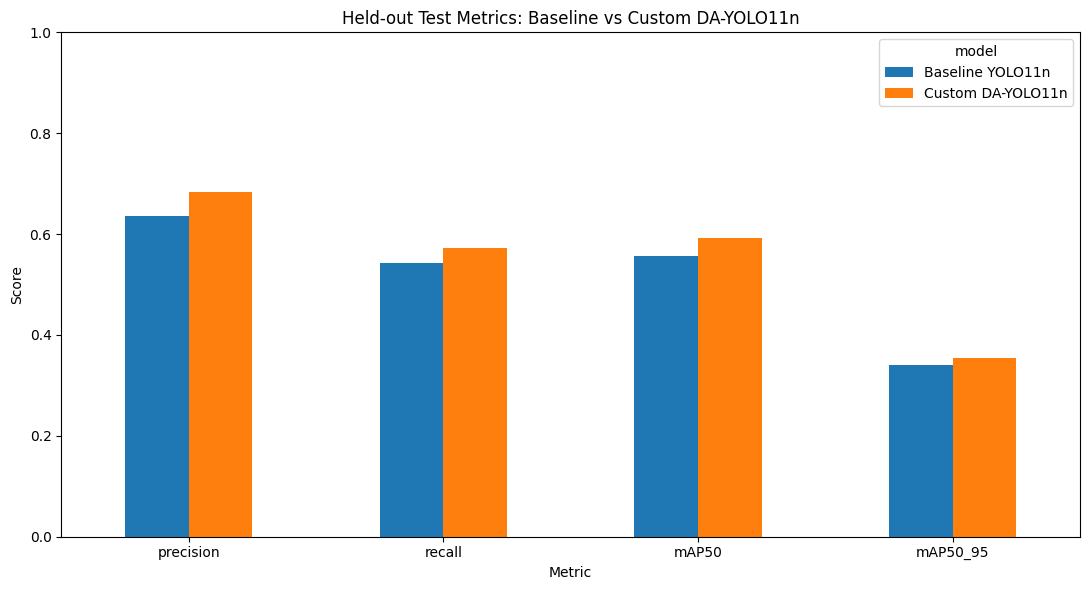

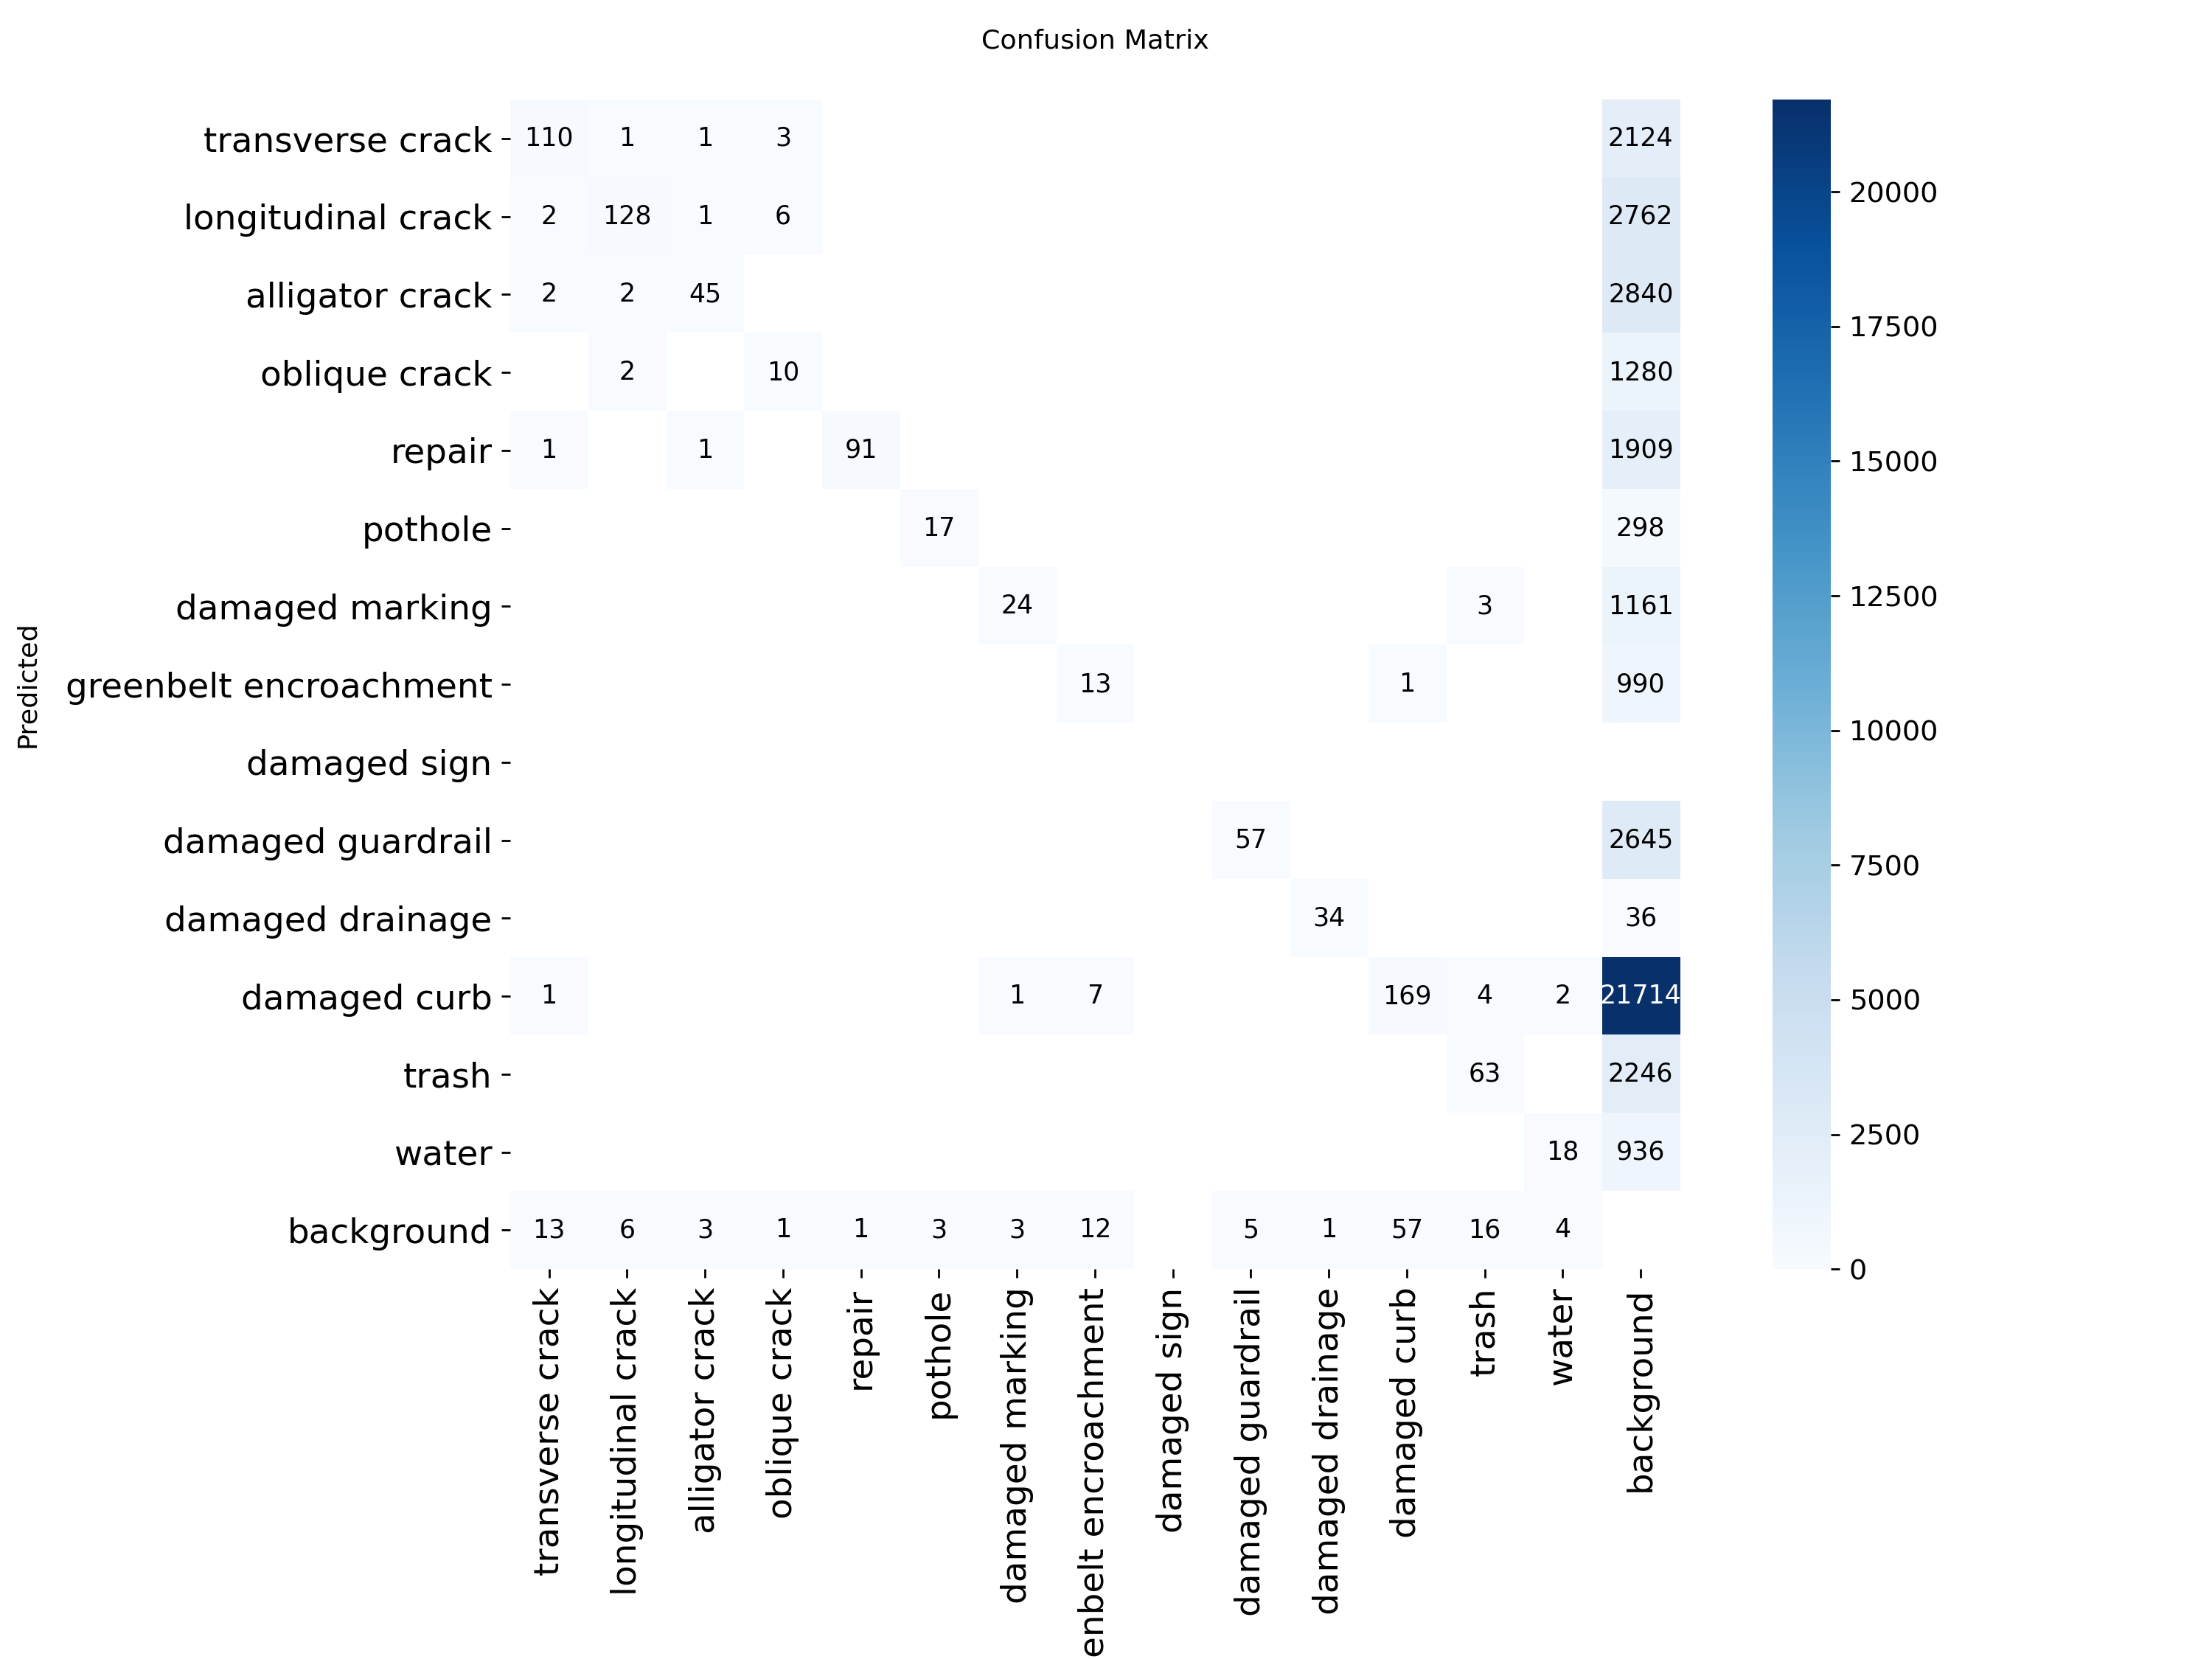

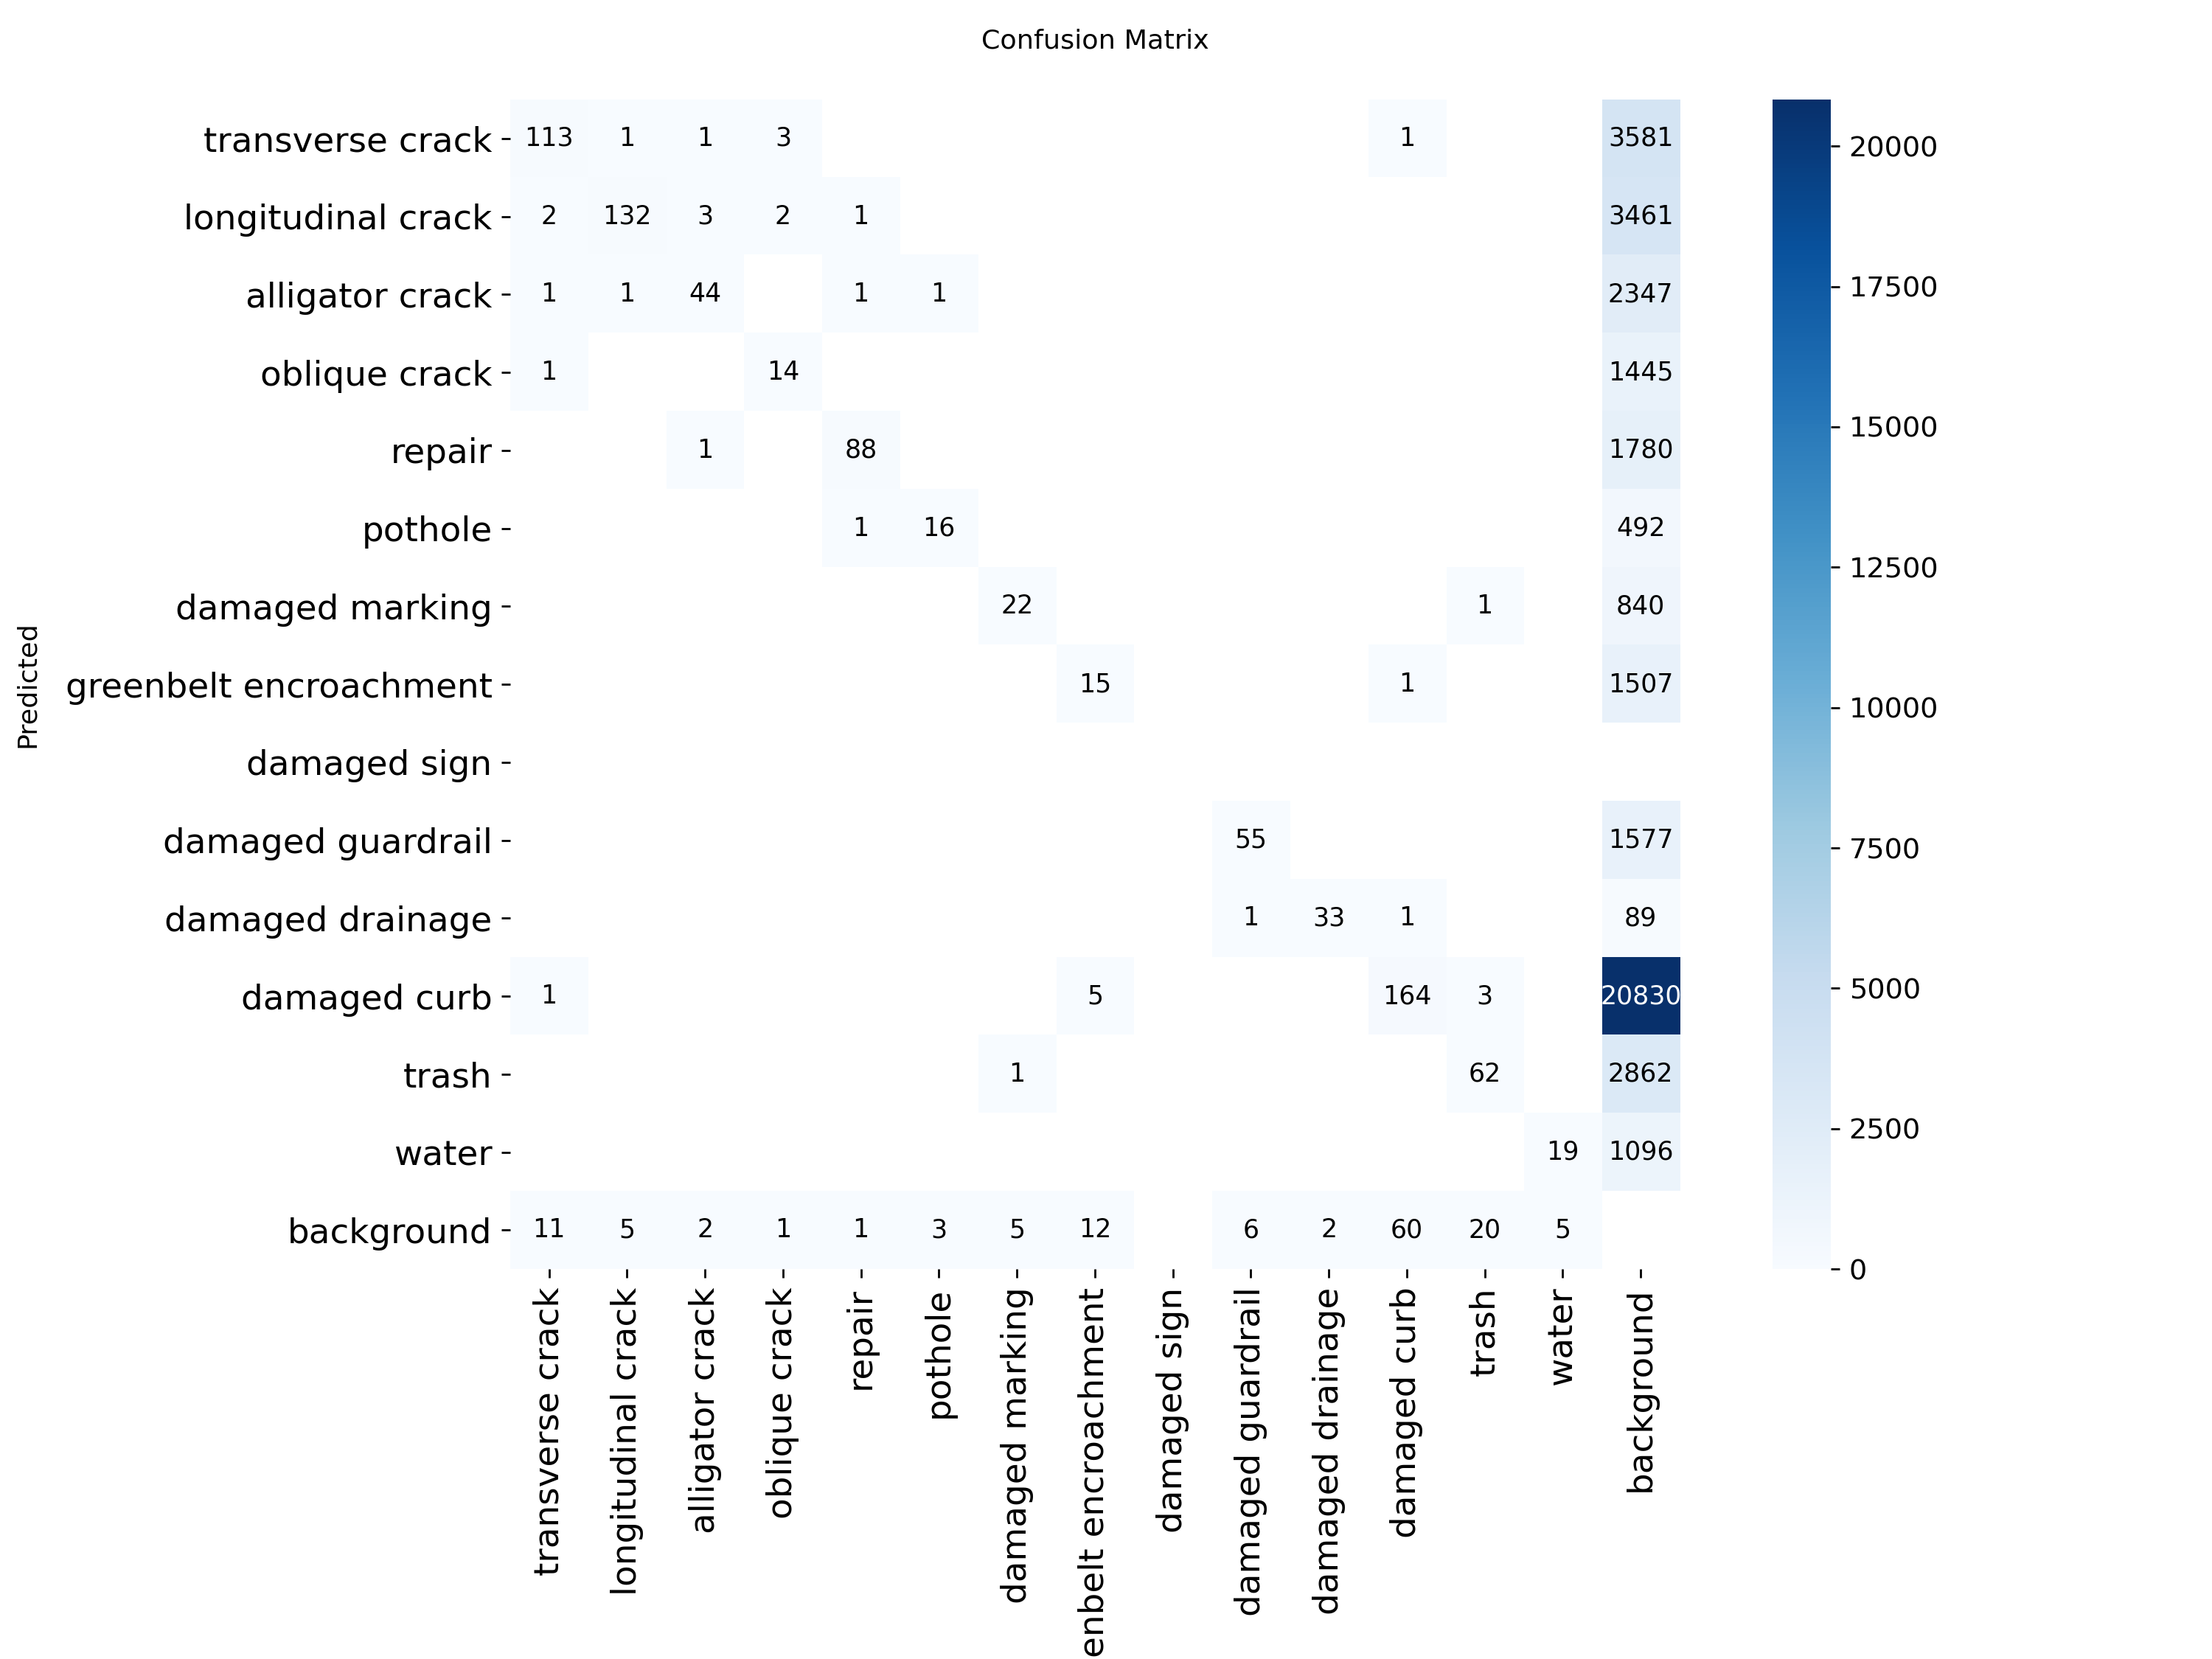

Test metrics and plots are generated from live evaluation results; no hard-coded metric values are used.


In [ ]:
# 7. Data-driven metric plots and confusion matrices
plot_df = summary.set_index('model')[['precision','recall','mAP50','mAP50_95']]
ax = plot_df.T.plot(kind='bar', figsize=(11,6))
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Held-out Test Metrics: Baseline vs Custom DA-YOLO11n')
ax.set_xlabel('Metric')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(PROJECT/'test_metric_comparison.png', dpi=160)
plt.show()

# Plot confusion matrices using each model's own saved test-evaluation artifact when present.
for label, run_name in [('Baseline YOLO11n','baseline_test'), ('Custom DA-YOLO11n','custom_da_test')]:
    cm_path = RUNS_DIR/run_name/'confusion_matrix.png'
    if cm_path.exists():
        from PIL import Image
        display(Image.open(cm_path))
    else:
        print(f'Confusion matrix image not found at {cm_path}; inspect the plots directory created by Ultralytics for {label}.')

print('Test metrics and plots are generated from live evaluation results; no hard-coded metric values are used.')


## 8. Qualitative test examples
The existing qualitative examples are preserved below.

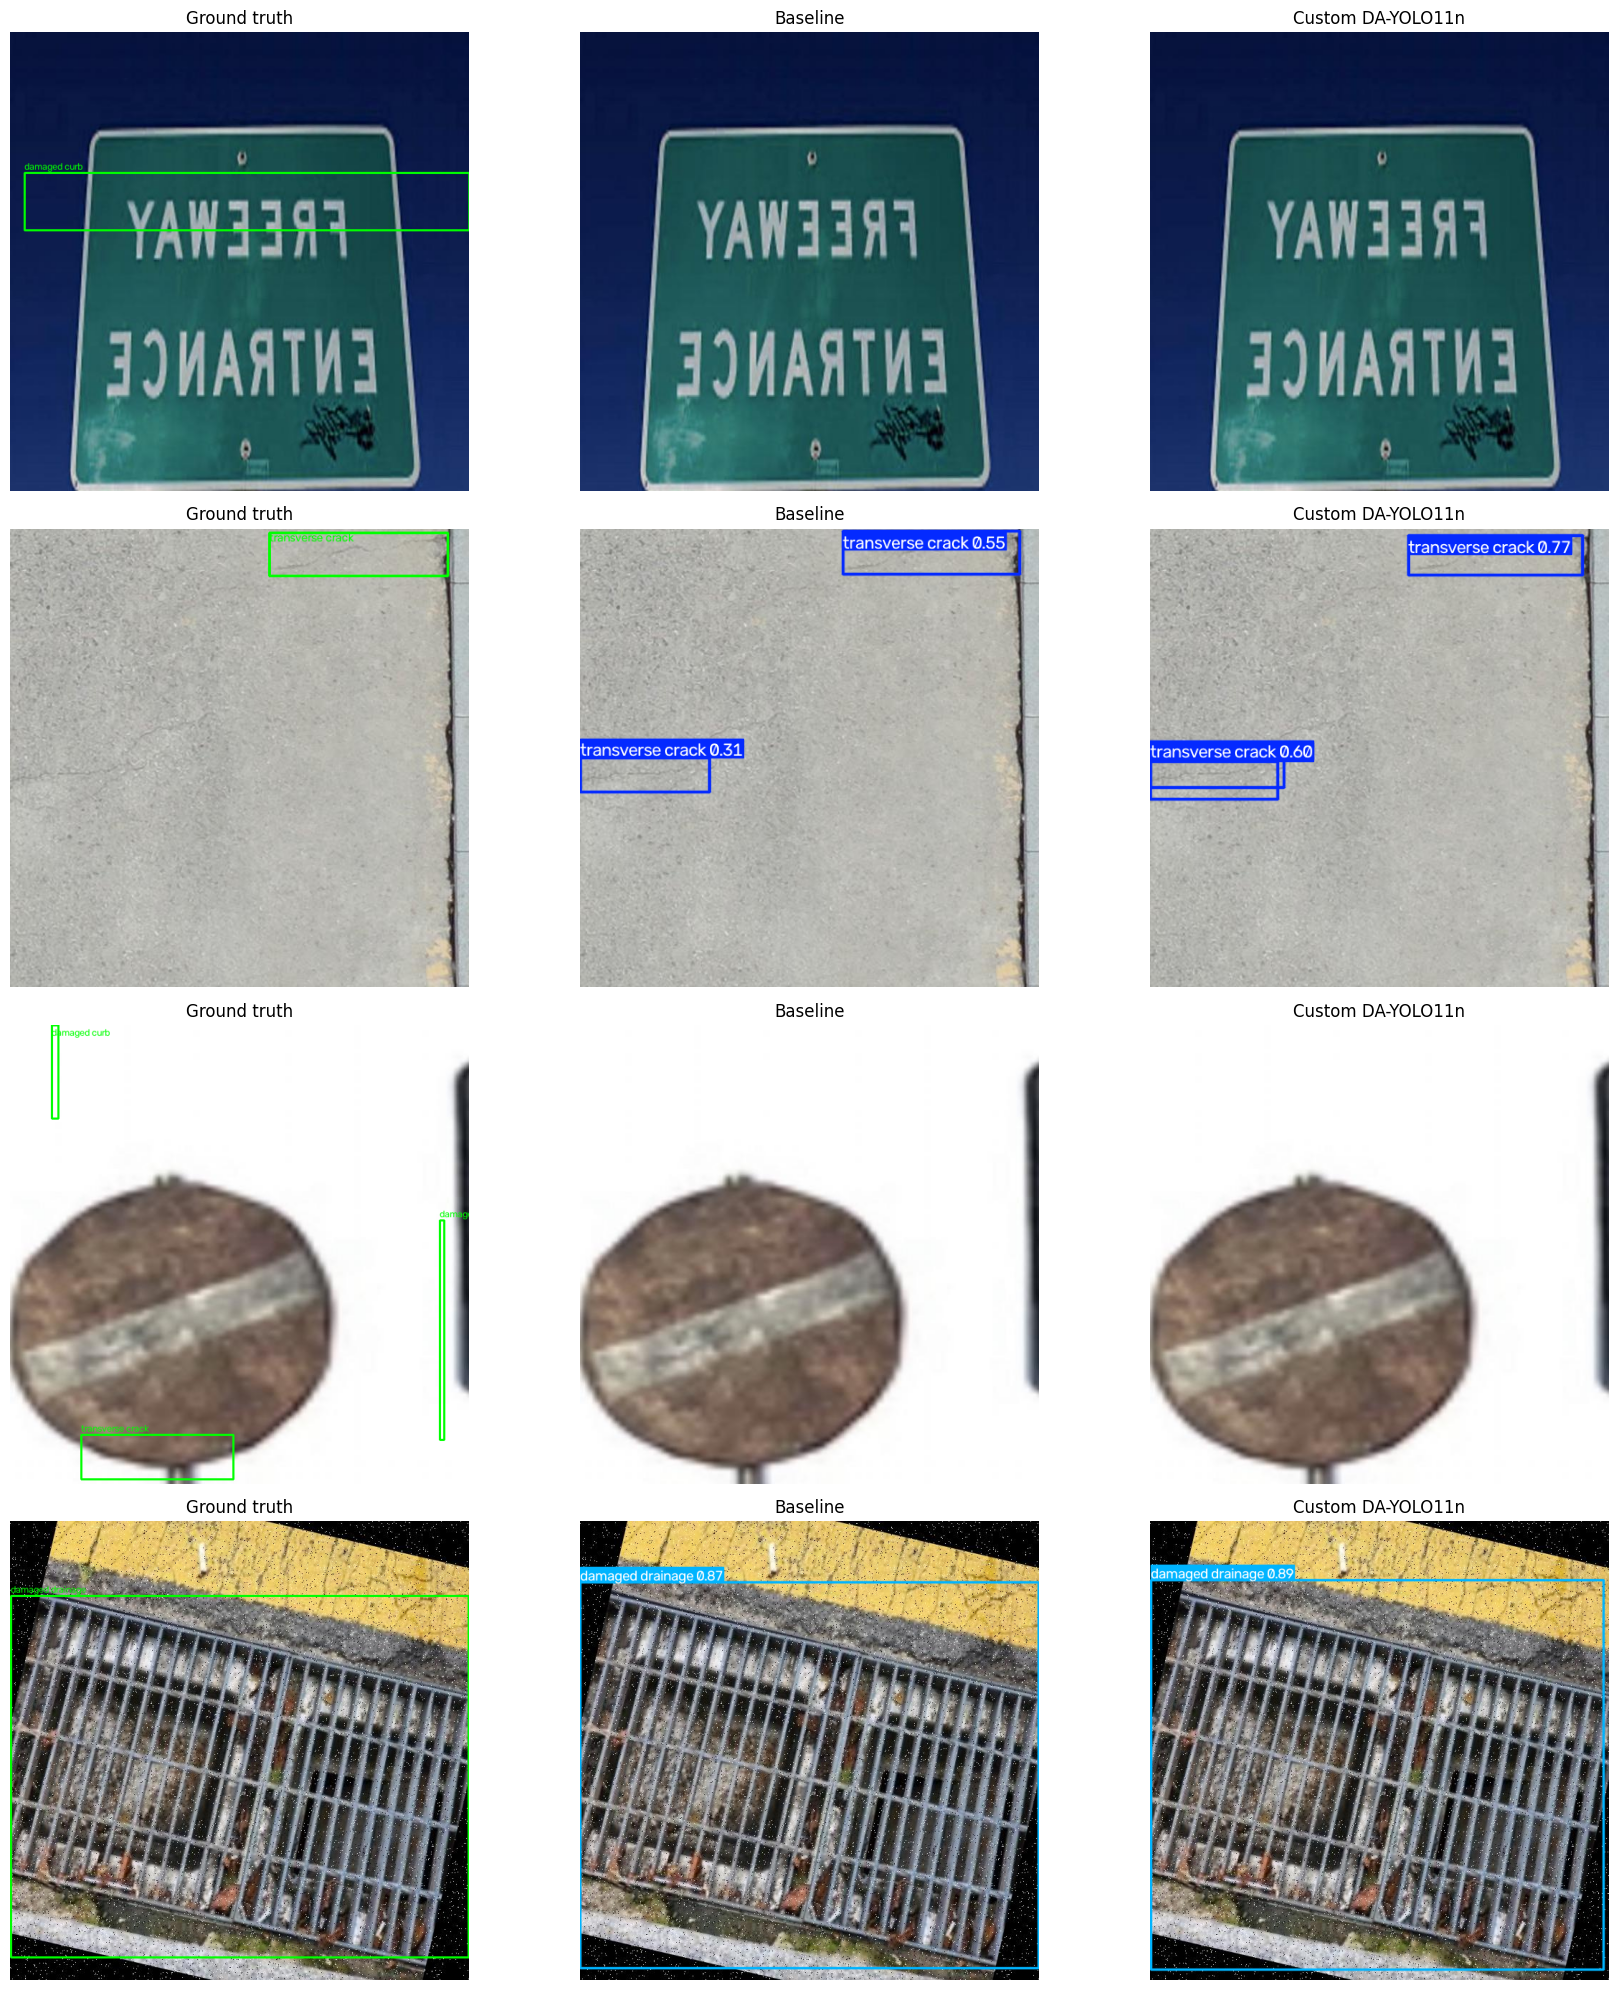

In [ ]:
# 8. Fixed, reproducible qualitative examples: ground truth vs model predictions
import cv2
from PIL import Image
val_rows = split_data['test']
viz_rng = random.Random(SEED)
selected = viz_rng.sample(val_rows, min(4, len(val_rows)))

def draw_gt(img_path, label_path):
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(img_path)
    h, w = img.shape[:2]
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue
            cls, xc, yc, bw, bh = line.split()
            cls = int(cls); xc, yc, bw, bh = map(float, (xc,yc,bw,bh))
            x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
            x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
            cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)
            cv2.putText(img, CLASS_NAMES[cls], (max(0,x1),max(15,y1-4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0,255,0), 1, cv2.LINE_AA)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(len(selected), 3, figsize=(18, 5*len(selected)))
if len(selected) == 1:
    axes = np.expand_dims(axes, 0)
for i, (src_img, _) in enumerate(selected):
    img_path = DATA_ROOT/'images'/'test'/src_img.name
    label_path = DATA_ROOT/'labels'/'test'/(src_img.stem+'.txt')
    axes[i,0].imshow(draw_gt(img_path, label_path)); axes[i,0].set_title('Ground truth'); axes[i,0].axis('off')
    r0 = baseline_best_model.predict(str(img_path), conf=0.25, verbose=False)[0]
    axes[i,1].imshow(cv2.cvtColor(r0.plot(), cv2.COLOR_BGR2RGB)); axes[i,1].set_title('Baseline'); axes[i,1].axis('off')
    r1 = custom_best_model.predict(str(img_path), conf=0.25, verbose=False)[0]
    axes[i,2].imshow(cv2.cvtColor(r1.plot(), cv2.COLOR_BGR2RGB)); axes[i,2].set_title('Custom DA-YOLO11n'); axes[i,2].axis('off')
plt.tight_layout()
plt.savefig(PROJECT/'test_qualitative_examples.png', dpi=160)
plt.show()


## 9. Additional final figures and tables
These existing figure-generation outputs are retained as well. They may overlap with Section 7, but are useful for the final report.

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Paths
PROJECT = Path("/content/uavroad_experiment")
RUNS_DIR = PROJECT / "runs"
OUT = PROJECT / "final_figures"
OUT.mkdir(parents=True, exist_ok=True)

summary_path = PROJECT / "test_metrics_summary.csv"
per_class_path = PROJECT / "per_class_test_ap.csv"

assert summary_path.exists(), f"Missing: {summary_path}"
assert per_class_path.exists(), f"Missing: {per_class_path}"

summary = pd.read_csv(summary_path)
per_class = pd.read_csv(per_class_path)

print("Overall test metrics:")
display(summary)

print("Per-class AP data:")
display(per_class.head())


Overall test metrics:


,model,precision,recall,mAP50,mAP50_95,parameters
0,Baseline YOLO11n,0.635283,0.541866,0.555854,0.339518,2608042
1,Custom DA-YOLO11n,0.684143,0.572588,0.593105,0.353702,2592570


Per-class AP data:


,model,class_id,class_name,AP50_95
0,Baseline YOLO11n,0,transverse crack,0.420925
1,Baseline YOLO11n,1,longitudinal crack,0.336531
2,Baseline YOLO11n,2,alligator crack,0.390211
3,Baseline YOLO11n,3,oblique crack,0.341738
4,Baseline YOLO11n,4,repair,0.692427


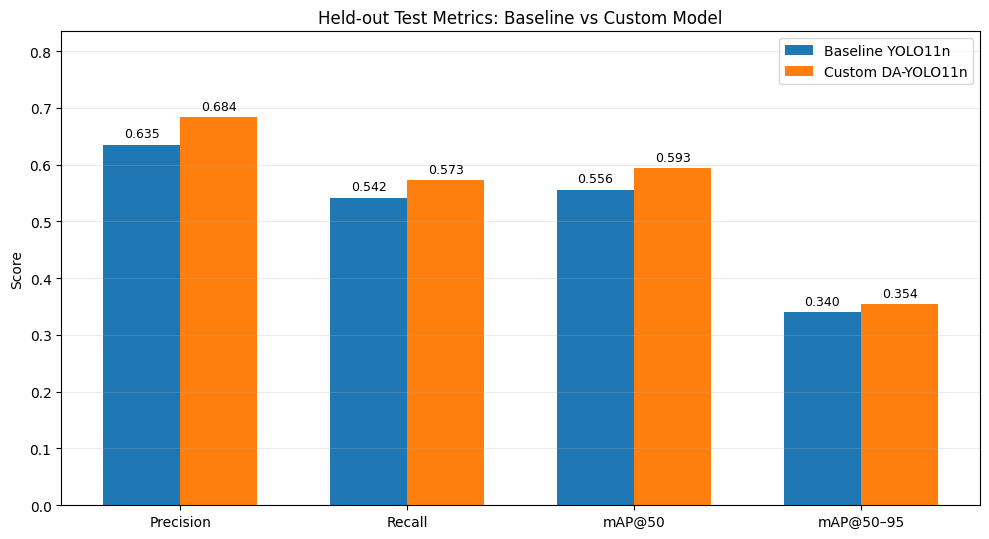

In [ ]:

metrics = ["precision", "recall", "mAP50", "mAP50_90", "mAP50_95"]
labels = ["Precision", "Recall", "mAP@50", "mAP@50–90", "mAP@50–95"]

x = np.arange(len(metrics))
width = 0.34

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, (_, row) in enumerate(summary.iterrows()):
    values = [row[m] for m in metrics]
    bars = ax.bar(
        x + (i - (len(summary)-1)/2) * width,
        values,
        width,
        label=row["model"]
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("Held-out Test Metrics: Baseline vs Custom Model")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, min(1.0, max(summary[metrics].max()) * 1.22))
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

fig.savefig(OUT / "overall_test_metrics.png", dpi=300, bbox_inches="tight")
plt.show()


Classes found in per-class results:
['alligator crack', 'damaged curb', 'damaged drainage', 'damaged guardrail', 'damaged marking', 'damaged sign', 'greenbelt encroachment', 'longitudinal crack', 'oblique crack', 'pothole', 'repair', 'transverse crack', 'trash', 'water']


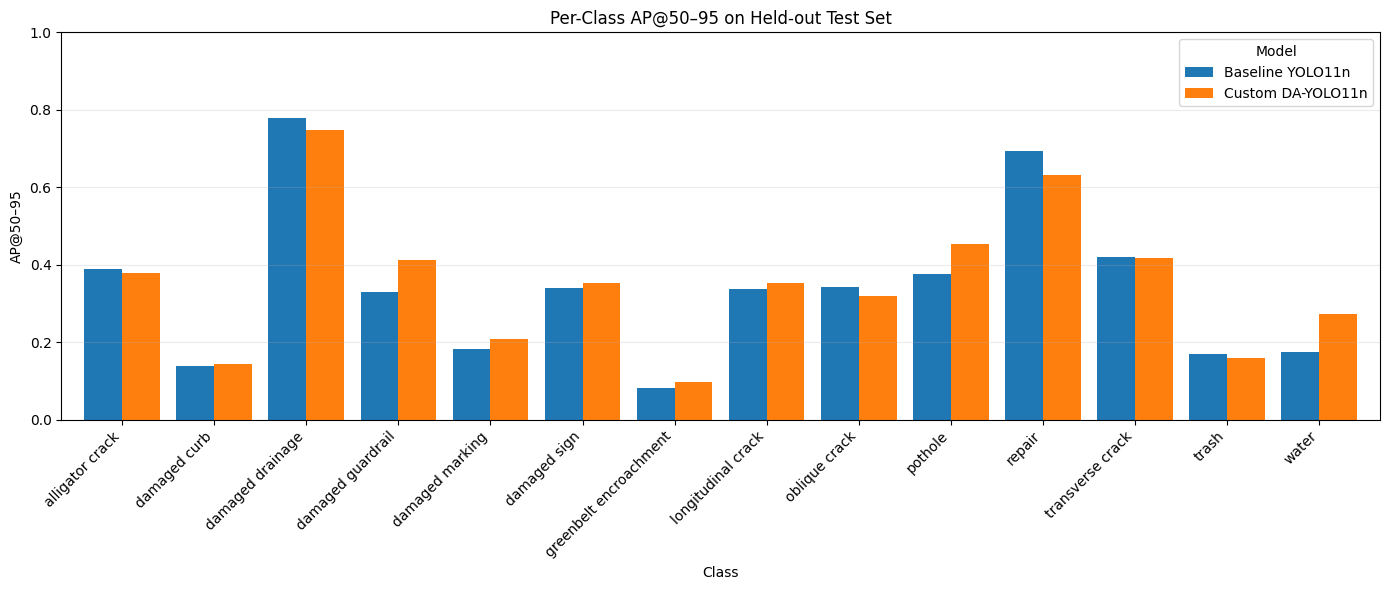

model,Baseline YOLO11n,Custom DA-YOLO11n,custom_minus_baseline
class_name,,,
alligator crack,0.3902,0.3784,-0.0118
damaged curb,0.1396,0.1437,0.0040
damaged drainage,0.7784,0.7485,-0.0299
damaged guardrail,0.3297,0.4115,0.0817
damaged marking,0.1816,0.2088,0.0272
damaged sign,0.3395,0.3537,0.0142
greenbelt encroachment,0.0810,0.0960,0.0150
longitudinal crack,0.3365,0.3540,0.0174
oblique crack,0.3417,0.3197,-0.0221


In [ ]:

# Verify expected columns
required = {"model", "class_name", "AP50_95"}
assert required.issubset(per_class.columns), (
    f"Expected columns: {required}; found {set(per_class.columns)}"
)

pivot = per_class.pivot(
    index="class_name",
    columns="model",
    values="AP50_95"
)

print("Classes found in per-class results:")
print(pivot.index.tolist())

ax = pivot.plot(kind="bar", figsize=(14, 6), width=0.82)
ax.set_title("Per-Class AP@50–95 on Held-out Test Set")
ax.set_xlabel("Class")
ax.set_ylabel("AP@50–95")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(OUT / "per_class_ap_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Numeric comparison table
comparison = pivot.copy()
comparison["custom_minus_baseline"] = (
    comparison.iloc[:, 1] - comparison.iloc[:, 0]
)
display(comparison.round(4))

comparison.to_csv(OUT / "per_class_ap_comparison.csv")


Baseline confusion matrix: /content/uavroad_experiment/runs/baseline_test/confusion_matrix.png
Custom confusion matrix: /content/uavroad_experiment/runs/custom_da_test/confusion_matrix.png


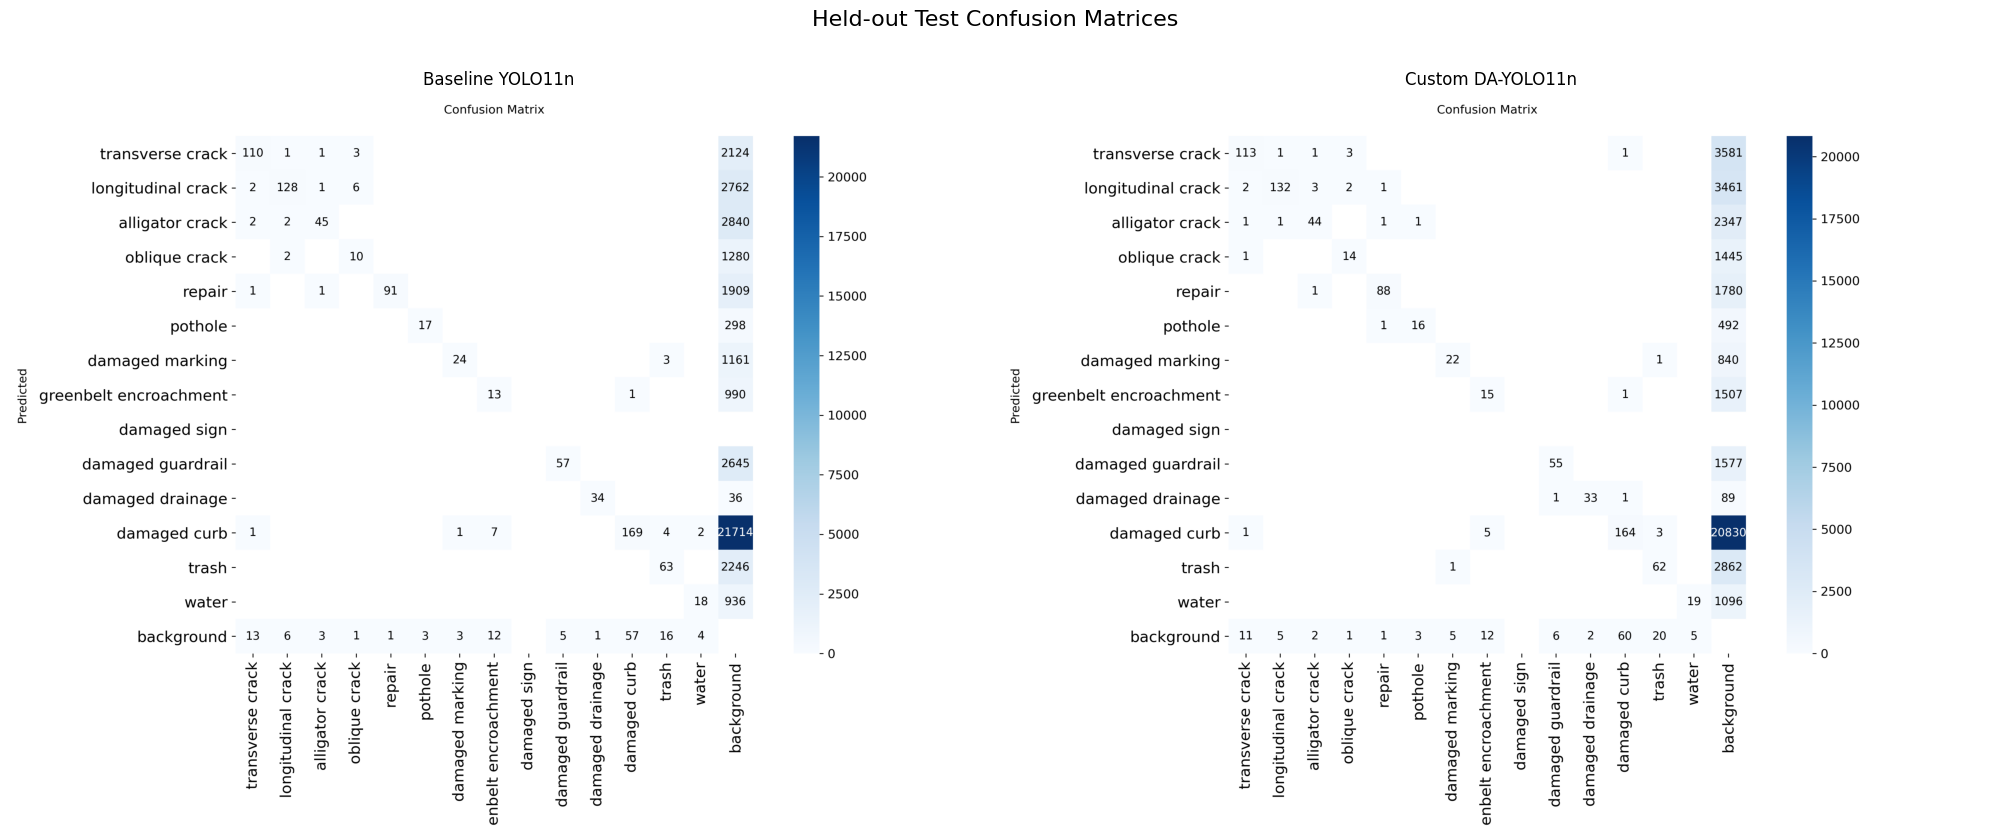

In [ ]:

def find_confusion_matrix(run_dir):
    candidates = [
        run_dir / "confusion_matrix.png",
        run_dir / "confusion_matrix_normalized.png",
    ]
    for path in candidates:
        if path.exists():
            return path
    return None

base_cm = find_confusion_matrix(RUNS_DIR / "baseline_test")
custom_cm = find_confusion_matrix(RUNS_DIR / "custom_da_test")

print("Baseline confusion matrix:", base_cm)
print("Custom confusion matrix:", custom_cm)

if base_cm is None or custom_cm is None:
    print(
        "A confusion matrix file was not found. Check the run folders "
        "and their filenames."
    )
else:
    img_base = Image.open(base_cm).convert("RGB")
    img_custom = Image.open(custom_cm).convert("RGB")

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    axes[0].imshow(img_base)
    axes[0].set_title("Baseline YOLO11n")
    axes[0].axis("off")

    axes[1].imshow(img_custom)
    axes[1].set_title("Custom DA-YOLO11n")
    axes[1].axis("off")

    fig.suptitle("Held-out Test Confusion Matrices", fontsize=16)
    fig.tight_layout()

    fig.savefig(
        OUT / "confusion_matrices_side_by_side.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


## 10. Reporting notes and limitations

- Report the held-out TEST metrics shown above.
- Both checkpoints were evaluated on the same test split and image size.
- Confirm the custom checkpoint's active modules before attributing gains specifically to the intended deformable-attention architecture.
- Verify class names and indices before publishing per-class AP. In particular, compare the dataset YAML class mapping with the rows printed by Ultralytics.
- Test results are for final reporting, not model selection or hyperparameter tuning.
- Some plots in this notebook are preserved outputs from the previous run. They remain visible in the notebook file; if you rerun a cell, its outputs may be replaced.


Testing models on image: sample.jpg

image 1/1 /content/sample.jpg: 448x640 2 trashs, 9.7ms
Speed: 1.5ms preprocess, 9.7ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-7

image 1/1 /content/sample.jpg: 448x640 3 trashs, 8.1ms
Speed: 1.6ms preprocess, 8.1ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict-8


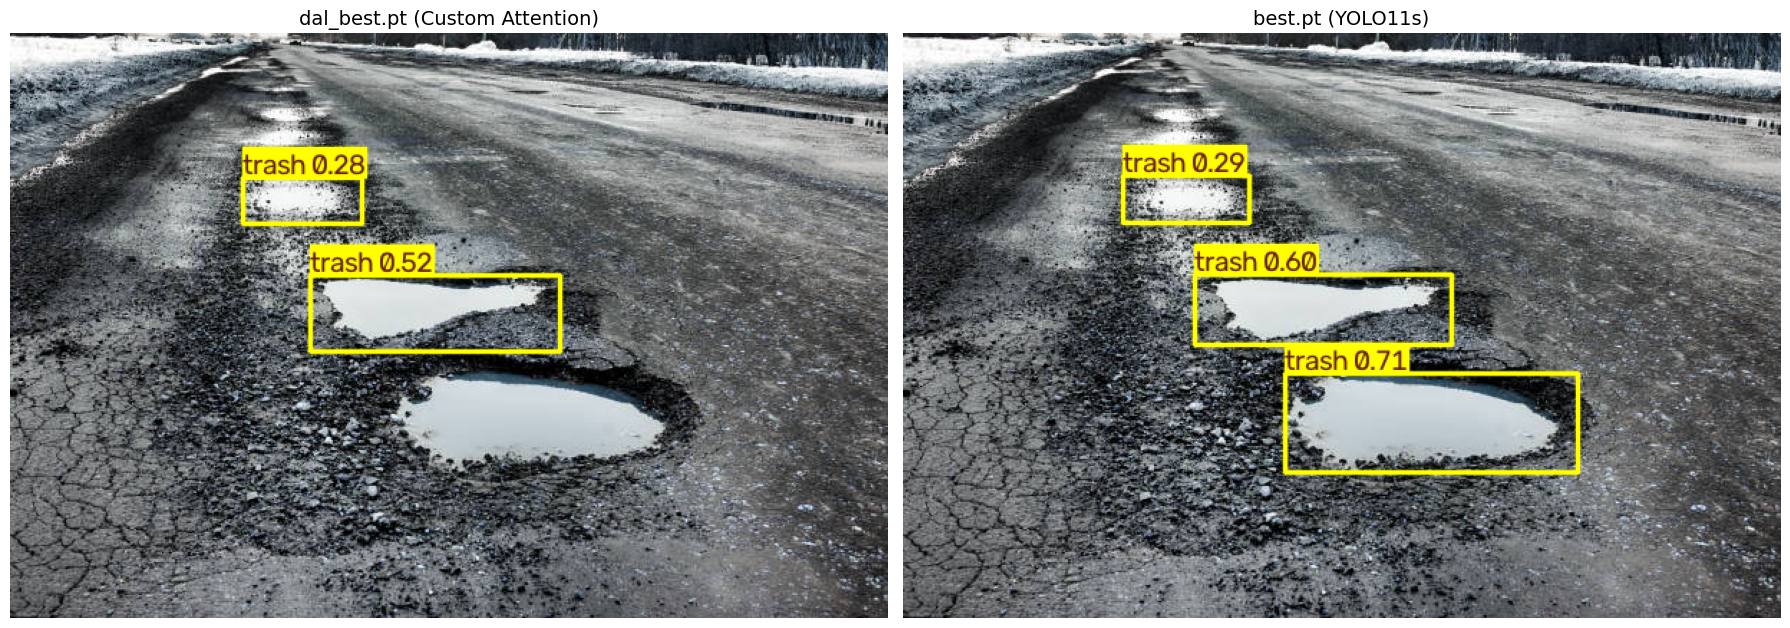

In [5]:
# 1. Install required dependencies
!pip install -q ultralytics

import os
import math
import torch
import torch.nn as nn
import torchvision.ops as tv_ops
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 2. Register custom model modules for unpickling dal_best.pt
class ConvBNAct(nn.Module):
    def __init__(self, c1, c2, k=1, s=1, p=None, groups=1):
        super().__init__()
        p = k // 2 if p is None else p
        self.conv = nn.Conv2d(c1, c2, k, s, p, groups=groups, bias=False)
        self.bn = nn.BatchNorm2d(c2)
        self.act = nn.SiLU()

    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

class DeformableConvBlock(nn.Module):
    def __init__(self, c1, c2, k=3, stride=1):
        super().__init__()
        self.k, self.stride, self.padding = k, stride, k // 2
        self.offset_mask = nn.Conv2d(c1, 3 * k * k, k, stride=stride, padding=self.padding)
        nn.init.zeros_(self.offset_mask.weight)
        nn.init.zeros_(self.offset_mask.bias)
        self.weight = nn.Parameter(torch.empty(c2, c1, k, k))
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        self.bn = nn.BatchNorm2d(c2)
        self.act = nn.SiLU()

    def forward(self, x):
        offsets = self.offset_mask(x)
        o1, o2, mask = torch.chunk(offsets, 3, dim=1)
        y = tv_ops.deform_conv2d(
            x, torch.cat([o1, o2], dim=1), self.weight,
            padding=self.padding, mask=mask.sigmoid(), stride=self.stride
        )
        return self.act(self.bn(y))

class DABottleneck(nn.Module):
    def __init__(self, c, shortcut=True):
        super().__init__()
        hidden = max(c // 2, 16)
        self.cv1 = ConvBNAct(c, hidden, 1)
        self.cv2 = DeformableConvBlock(hidden, c, 3)
        self.add = bool(shortcut)

    def forward(self, x):
        y = self.cv2(self.cv1(x))
        return x + y if self.add else y

class C3k2_DAttention(nn.Module):
    def __init__(self, c1, c2, n=2, shortcut=True, e=0.5):
        super().__init__()
        hidden = max(int(c2 * e), 16)
        self.cv1 = ConvBNAct(c1, hidden, 1)
        self.cv2 = ConvBNAct(c1, hidden, 1)
        self.cv3 = ConvBNAct(2 * hidden, c2, 1)
        self.m = nn.Sequential(*[DABottleneck(hidden, shortcut=(shortcut and c1 == c2)) for _ in range(n)])

    def forward(self, x):
        return self.cv3(torch.cat((self.m(self.cv1(x)), self.cv2(x)), dim=1))

# 3. Locate or prompt upload for sample image
supported_exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
checkpoints_files = {'dal_best.pt', 'best.pt'}
image_files = [f for f in os.listdir('.') if f.lower().endswith(supported_exts) and f not in checkpoints_files]

if not image_files:
    print("No image file found in working directory. Uploading sample image...")
    try:
        from google.colab import files
        uploaded = files.upload()
        image_files = [f for f in uploaded.keys() if f.lower().endswith(supported_exts)]
    except Exception as e:
        raise FileNotFoundError("Could not trigger Colab file upload. Upload an image manually to the current directory.") from e

if not image_files:
    raise FileNotFoundError("No supported image file uploaded.")

sample_image = image_files[0]
print(f"Testing models on image: {sample_image}")

# 4. Check for both model checkpoints
for path in ['dal_best.pt', 'best.pt']:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Checkpoint file '{path}' not found in current session directory.")

# 5. Run inference on both models
model_dal = YOLO('dal_best.pt')
res_dal = model_dal.predict(source=sample_image, imgsz=640, conf=0.25, save=True)[0]

model_yolo11s = YOLO('best.pt')
res_yolo11s = model_yolo11s.predict(source=sample_image, imgsz=640, conf=0.25, save=True)[0]

# 6. Side-by-side visual comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(res_dal.plot())
axes[0].set_title("dal_best.pt (Custom Attention)", fontsize=14)
axes[0].axis('off')

axes[1].imshow(res_yolo11s.plot())
axes[1].set_title("best.pt (YOLO11s)", fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()